![No CAP Project](nocap.png)

_Authored by La’ Neyshia Drew, Lucas Carreira, Matthew Konar, Sarah Baeza, and Sierra Mullins_

# Phase Two: Exploratory Data Analysis & Baseline Modeling

# Load Data

Load data in CSV format from HCDR datatset to a folder called "data"

In [10]:
import os
import pandas as pd
import numpy as np

DATA_DIR = "/root/shared/group1-hcdr-no-cap/data"  # container path, see README

# Check that Python can find the folder
print(os.listdir(DATA_DIR))

['application_test.csv', 'HomeCredit_columns_description.csv', 'POS_CASH_balance.csv', 'credit_card_balance.csv', 'installments_payments.csv', 'application_train.csv', 'bureau.csv', 'previous_application.csv', 'bureau_balance.csv', 'sample_submission.csv']


In [8]:
# Find all CSV files
csv_files = [f for f in os.listdir(DATA_DIR) if f.endswith(".csv")]

# Load each CSV into a dictionary
data = {}

for file in csv_files:
    name = file.replace(".csv", "")
    data[name] = pd.read_csv(
        os.path.join(DATA_DIR, file),
        encoding="latin1"
    )
    print(f"{name}: {data[name].shape}")

application_test: (48744, 121)
HomeCredit_columns_description: (219, 5)
POS_CASH_balance: (10001358, 8)
credit_card_balance: (3840312, 23)
installments_payments: (13605401, 8)
application_train: (307511, 122)
bureau: (1716428, 17)
previous_application: (1670214, 37)
bureau_balance: (27299925, 3)
sample_submission: (48744, 2)


Column Descriptions

In [9]:
# Load Home Credit column descriptions
column_descriptions = pd.read_csv(
    os.path.join(DATA_DIR, "HomeCredit_columns_description.csv"),
    encoding="latin1"
)

# Display the entire table
pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", None)

display(column_descriptions)

,Unnamed: 0,Table,Row,Description,Special
0,1,application_{train|test}.csv,SK_ID_CURR,ID of loan in our sample,NaN
1,2,application_{train|test}.csv,TARGET,"Target variable (1 - client with payment difficulties: he/she had late payment more than X days on at least one of the first Y installments of the loan in our sample, 0 - all other cases)",NaN
2,5,application_{train|test}.csv,NAME_CONTRACT_TYPE,Identification if loan is cash or revolving,NaN
3,6,application_{train|test}.csv,CODE_GENDER,Gender of the client,NaN
4,7,application_{train|test}.csv,FLAG_OWN_CAR,Flag if the client owns a car,NaN
5,8,application_{train|test}.csv,FLAG_OWN_REALTY,Flag if client owns a house or flat,NaN
6,9,application_{train|test}.csv,CNT_CHILDREN,Number of children the client has,NaN
7,10,application_{train|test}.csv,AMT_INCOME_TOTAL,Income of the client,NaN
8,11,application_{train|test}.csv,AMT_CREDIT,Credit amount of the loan,NaN
9,12,application_{train|test}.csv,AMT_ANNUITY,Loan annuity,NaN


## Dataset Descriptions

* __application_train/application_test:__ the main training and testing data with information about each loan application at Home Credit. Every loan has its own row and is identified by the feature SK_ID_CURR. The training application data comes with the TARGET indicating __0: the loan was repaid__ or __1: the loan was not repaid__. The target variable defines if the client had payment difficulties meaning he/she had late payment more than X days on at least one of the first Y installments of the loan. Such case is marked as 1 while other all other cases as 0.
* __bureau:__ data concerning client's previous credits from other financial institutions. Each previous credit has its own row in bureau, but one loan in the application data can have multiple previous credits.
* __bureau_balance:__ monthly data about the previous credits in bureau. Each row is one month of a previous credit, and a single previous credit can have multiple rows, one for each month of the credit length.
* __previous_application:__ previous applications for loans at Home Credit of clients who have loans in the application data. Each current loan in the application data can have multiple previous loans. Each previous application has one row and is identified by the feature SK_ID_PREV.
* __POS_CASH_BALANCE:__ monthly data about previous point of sale or cash loans clients have had with Home Credit. Each row is one month of a previous point of sale or cash loan, and a single previous loan can have many rows.
* credit_card_balance: monthly data about previous credit cards clients have had with Home Credit. Each row is one month of a credit card balance, and a single credit card can have many rows.
* __installments_payment:__ payment history for previous loans at Home Credit. There is one row for every made payment and one row for every missed payment.

# Exploratory Data Analysis

## Data Summary - Size, Variables and Target

In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load training data
application_train = pd.read_csv(
    os.path.join(DATA_DIR, "application_train.csv")
)

# Basic overview
print("Dataset shape:", application_train.shape)
display(application_train.head())

# Data types and non-null counts
application_train.info()

# Summary statistics (top ten features)
display(application_train.describe().T.head(10))

Dataset shape: (307511, 122)


,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_TYPE_SUITE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,DAYS_REGISTRATION,DAYS_ID_PUBLISH,OWN_CAR_AGE,FLAG_MOBIL,FLAG_EMP_PHONE,FLAG_WORK_PHONE,FLAG_CONT_MOBILE,FLAG_PHONE,FLAG_EMAIL,OCCUPATION_TYPE,CNT_FAM_MEMBERS,REGION_RATING_CLIENT,REGION_RATING_CLIENT_W_CITY,WEEKDAY_APPR_PROCESS_START,HOUR_APPR_PROCESS_START,REG_REGION_NOT_LIVE_REGION,REG_REGION_NOT_WORK_REGION,LIVE_REGION_NOT_WORK_REGION,REG_CITY_NOT_LIVE_CITY,REG_CITY_NOT_WORK_CITY,LIVE_CITY_NOT_WORK_CITY,ORGANIZATION_TYPE,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3,APARTMENTS_AVG,BASEMENTAREA_AVG,YEARS_BEGINEXPLUATATION_AVG,YEARS_BUILD_AVG,COMMONAREA_AVG,ELEVATORS_AVG,ENTRANCES_AVG,FLOORSMAX_AVG,FLOORSMIN_AVG,LANDAREA_AVG,LIVINGAPARTMENTS_AVG,LIVINGAREA_AVG,NONLIVINGAPARTMENTS_AVG,NONLIVINGAREA_AVG,APARTMENTS_MODE,BASEMENTAREA_MODE,YEARS_BEGINEXPLUATATION_MODE,YEARS_BUILD_MODE,COMMONAREA_MODE,ELEVATORS_MODE,ENTRANCES_MODE,FLOORSMAX_MODE,FLOORSMIN_MODE,LANDAREA_MODE,LIVINGAPARTMENTS_MODE,LIVINGAREA_MODE,NONLIVINGAPARTMENTS_MODE,NONLIVINGAREA_MODE,APARTMENTS_MEDI,BASEMENTAREA_MEDI,YEARS_BEGINEXPLUATATION_MEDI,YEARS_BUILD_MEDI,COMMONAREA_MEDI,ELEVATORS_MEDI,ENTRANCES_MEDI,FLOORSMAX_MEDI,FLOORSMIN_MEDI,LANDAREA_MEDI,LIVINGAPARTMENTS_MEDI,LIVINGAREA_MEDI,NONLIVINGAPARTMENTS_MEDI,NONLIVINGAREA_MEDI,FONDKAPREMONT_MODE,HOUSETYPE_MODE,TOTALAREA_MODE,WALLSMATERIAL_MODE,EMERGENCYSTATE_MODE,OBS_30_CNT_SOCIAL_CIRCLE,DEF_30_CNT_SOCIAL_CIRCLE,OBS_60_CNT_SOCIAL_CIRCLE,DEF_60_CNT_SOCIAL_CIRCLE,DAYS_LAST_PHONE_CHANGE,FLAG_DOCUMENT_2,FLAG_DOCUMENT_3,FLAG_DOCUMENT_4,FLAG_DOCUMENT_5,FLAG_DOCUMENT_6,FLAG_DOCUMENT_7,FLAG_DOCUMENT_8,FLAG_DOCUMENT_9,FLAG_DOCUMENT_10,FLAG_DOCUMENT_11,FLAG_DOCUMENT_12,FLAG_DOCUMENT_13,FLAG_DOCUMENT_14,FLAG_DOCUMENT_15,FLAG_DOCUMENT_16,FLAG_DOCUMENT_17,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,351000.0,Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.018801,-9461,-637,-3648.0,-2120,NaN,1,1,0,1,1,0,Laborers,1.0,2,2,WEDNESDAY,10,0,0,0,0,0,0,Business Entity Type 3,0.083037,0.262949,0.139376,0.0247,0.0369,0.9722,0.6192,0.0143,0.00,0.0690,0.0833,0.1250,0.0369,0.0202,0.0190,0.0000,0.0000,0.0252,0.0383,0.9722,0.6341,0.0144,0.0000,0.0690,0.0833,0.1250,0.0377,0.022,0.0198,0.0,0.0,0.0250,0.0369,0.9722,0.6243,0.0144,0.00,0.0690,0.0833,0.1250,0.0375,0.0205,0.0193,0.0000,0.00,reg oper account,block of flats,0.0149,"Stone, brick",No,2.0,2.0,2.0,2.0,-1134.0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,1129500.0,Family,State servant,Higher education,Married,House / apartment,0.003541,-16765,-1188,-1186.0,-291,NaN,1,1,0,1,1,0,Core staff,2.0,1,1,MONDAY,11,0,0,0,0,0,0,School,0.311267,0.622246,NaN,0.0959,0.0529,0.9851,0.7960,0.0605,0.08,0.0345,0.2917,0.3333,0.0130,0.0773,0.0549,0.0039,0.0098,0.0924,0.0538,0.9851,0.8040,0.0497,0.0806,0.0345,0.2917,0.3333,0.0128,0.079,0.0554,0.0,0.0,0.0968,0.0529,0.9851,0.7987,0.0608,0.08,0.0345,0.2917,0.3333,0.0132,0.0787,0.0558,0.0039,0.01,reg oper account,block of flats,0.0714,Block,No,1.0,0.0,1.0,0.0,-828.0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,135000.0,Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.010032,-19046,-225,-4260.0,-2531,26.0,1,1,1,1,1,0,Laborers,1.0,2,2,MONDAY,9,0,0,0,0,0,0,Government,NaN,0.555912,0.729567,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 307511 entries, 0 to 307510
Columns: 122 entries, SK_ID_CURR to AMT_REQ_CREDIT_BUREAU_YEAR
dtypes: float64(65), int64(41), object(16)
memory usage: 286.2+ MB


,count,mean,std,min,25%,50%,75%,max
SK_ID_CURR,307511.0,278180.518577,102790.175348,100002.00000,189145.500000,278202.00000,367142.500000,4.562550e+05
TARGET,307511.0,0.080729,0.272419,0.00000,0.000000,0.00000,0.000000,1.000000e+00
CNT_CHILDREN,307511.0,0.417052,0.722121,0.00000,0.000000,0.00000,1.000000,1.900000e+01
AMT_INCOME_TOTAL,307511.0,168797.919297,237123.146279,25650.00000,112500.000000,147150.00000,202500.000000,1.170000e+08
AMT_CREDIT,307511.0,599025.999706,402490.776996,45000.00000,270000.000000,513531.00000,808650.000000,4.050000e+06
AMT_ANNUITY,307499.0,27108.573909,14493.737315,1615.50000,16524.000000,24903.00000,34596.000000,2.580255e+05
AMT_GOODS_PRICE,307233.0,538396.207429,369446.460540,40500.00000,238500.000000,450000.00000,679500.000000,4.050000e+06
REGION_POPULATION_RELATIVE,307511.0,0.020868,0.013831,0.00029,0.010006,0.01885,0.028663,7.250800e-02
DAYS_BIRTH,307511.0,-16036.995067,4363.988632,-25229.00000,-19682.000000,-15750.00000,-12413.000000,-7.489000e+03
DAYS_EMPLOYED,307511.0,63815.045904,141275.766519,-17912.00000,-2760.000000,-1213.00000,-289.000000,3.652430e+05


There are 307,511 applicants and 122 columns, including the target variable and ID number. 

## Analyze Target

0 = applicant did not experience payment difficulties. 

1 = applicant experienced payment difficulties.

0    282686
1     24825
Name: TARGET, dtype: int64
0    91.927118
1     8.072882
Name: TARGET, dtype: float64


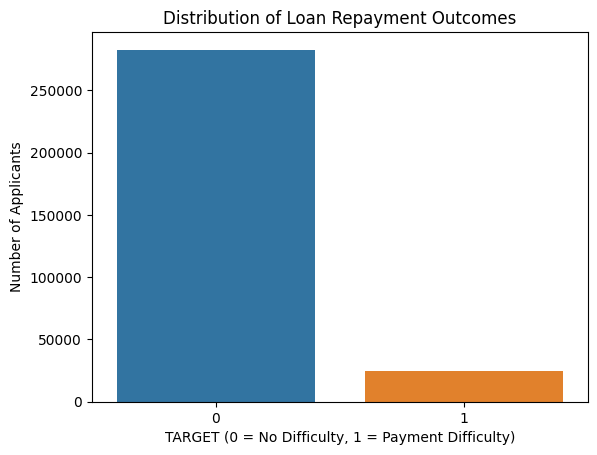

In [12]:
# Target counts
print(application_train["TARGET"].value_counts())

# Target percentages
print(application_train["TARGET"].value_counts(normalize=True) * 100)

# Visualize target distribution
sns.countplot(data=application_train, x="TARGET")
plt.title("Distribution of Loan Repayment Outcomes")
plt.xlabel("TARGET (0 = No Difficulty, 1 = Payment Difficulty)")
plt.ylabel("Number of Applicants")
plt.show()

About 8% of the sample experiences payment dificulty.

## Missing Values and Duplicate Rows

In [17]:
# Calculate missing values
missing = pd.DataFrame({
    "Missing Count": application_train.isnull().sum(),
    "Missing Percentage": application_train.isnull().mean() * 100
})

# Keep columns with missing values
missing = missing[missing["Missing Count"] > 0]

# Sort by missing percentage
missing = missing.sort_values(
    by="Missing Percentage",
    ascending=False
)

display(missing.head(30))

,Missing Count,Missing Percentage
COMMONAREA_MEDI,214865,69.872297
COMMONAREA_AVG,214865,69.872297
COMMONAREA_MODE,214865,69.872297
NONLIVINGAPARTMENTS_MEDI,213514,69.432963
NONLIVINGAPARTMENTS_MODE,213514,69.432963
NONLIVINGAPARTMENTS_AVG,213514,69.432963
FONDKAPREMONT_MODE,210295,68.386172
LIVINGAPARTMENTS_MODE,210199,68.354953
LIVINGAPARTMENTS_MEDI,210199,68.354953
LIVINGAPARTMENTS_AVG,210199,68.354953


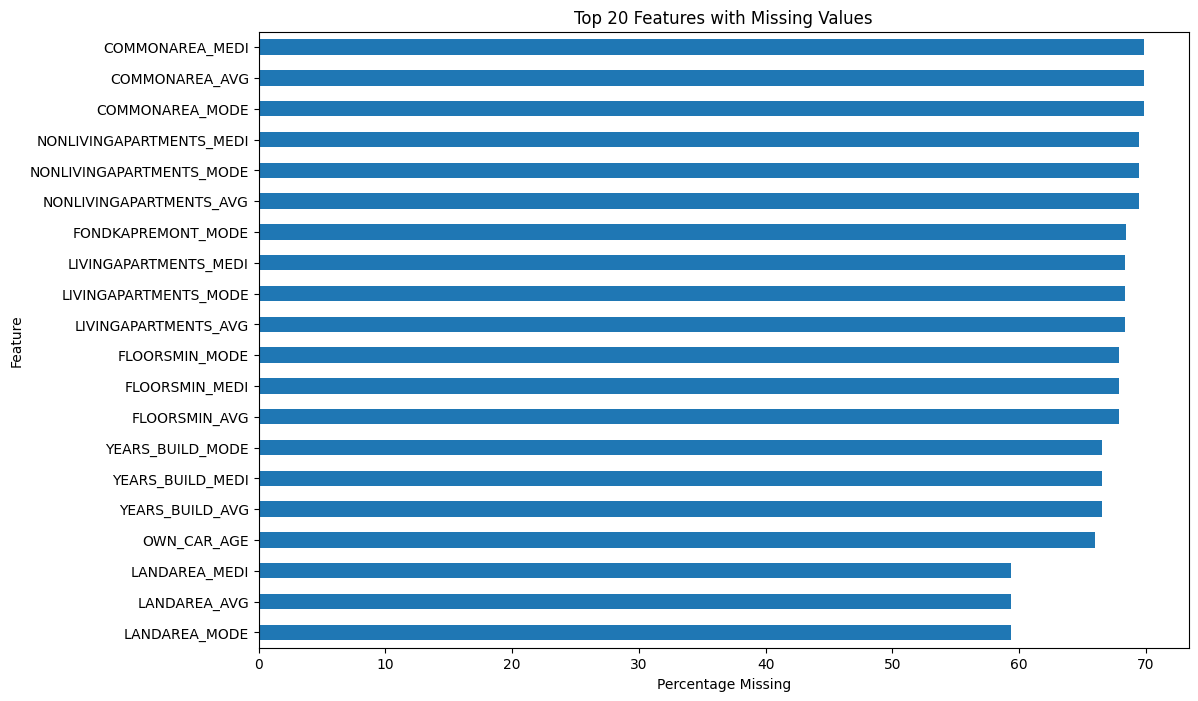

In [18]:
plt.figure(figsize=(12, 8))

missing.head(20)["Missing Percentage"].sort_values().plot(
    kind="barh"
)

plt.title("Top 20 Features with Missing Values")
plt.xlabel("Percentage Missing")
plt.ylabel("Feature")
plt.show()

In [33]:
# Check duplicate applicant IDs
print("Duplicate applicant IDs:",
      application_train["SK_ID_CURR"].duplicated().sum())

# Check duplicate rows
print("Duplicate rows:",
      application_train.duplicated().sum())

# Check unusual employment values
print(application_train["DAYS_EMPLOYED"].value_counts().head())

# Check unique values in binary columns
binary_features = [
    "FLAG_OWN_CAR",
    "FLAG_OWN_REALTY",
    "CODE_GENDER"
]

for col in binary_features:
    print(f"\n{col}:")
    print(application_train[col].value_counts(dropna=False))

Duplicate applicant IDs: 0
Duplicate rows: 0
 365243    55374
-200         156
-224         152
-230         151
-199         151
Name: DAYS_EMPLOYED, dtype: int64

FLAG_OWN_CAR:
N    202924
Y    104587
Name: FLAG_OWN_CAR, dtype: int64

FLAG_OWN_REALTY:
Y    213312
N     94199
Name: FLAG_OWN_REALTY, dtype: int64

CODE_GENDER:
F      202448
M      105059
XNA         4
Name: CODE_GENDER, dtype: int64


## Visualize Variables

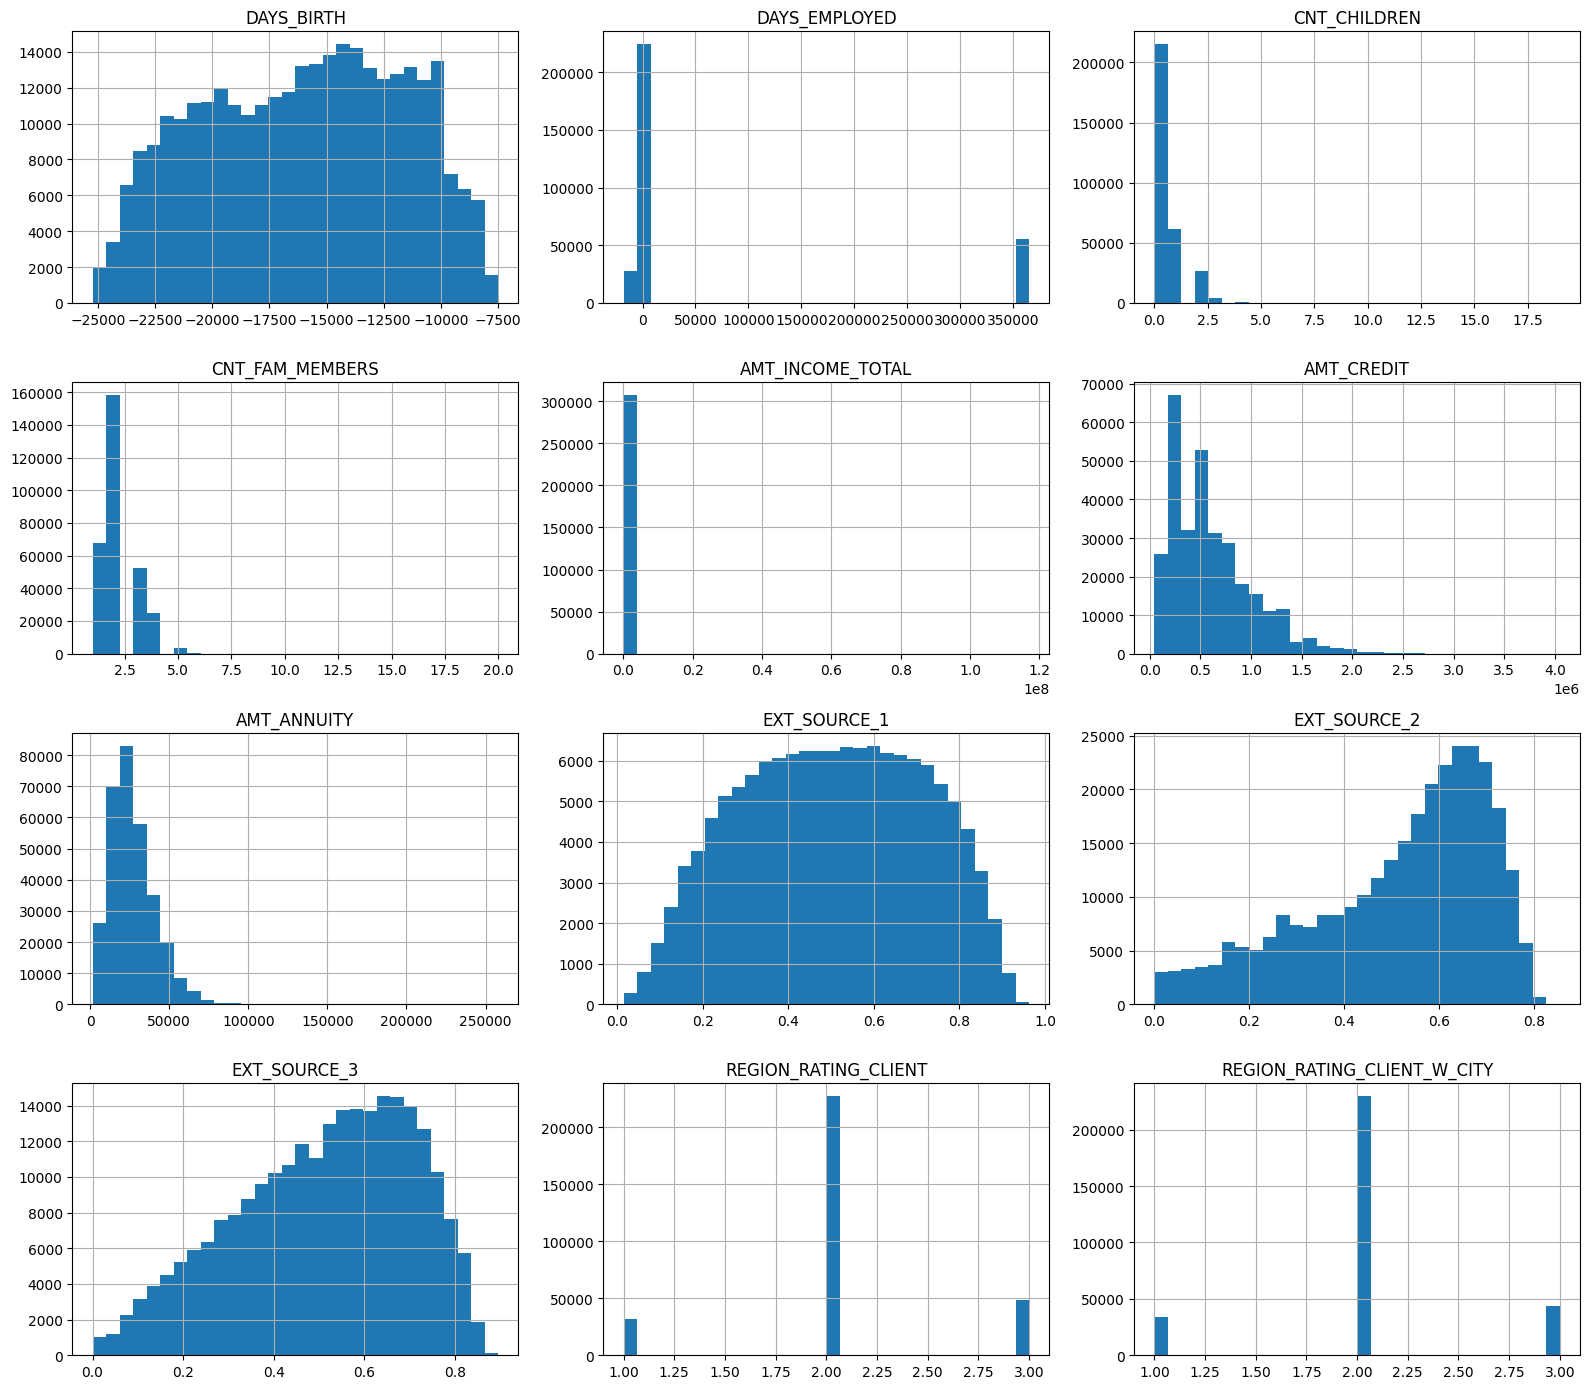

In [21]:
numerical_features = [
    # Applicant demographics
    "DAYS_BIRTH",                  # Age
    "DAYS_EMPLOYED",               # Employment duration
    "CNT_CHILDREN",                # Number of children
    "CNT_FAM_MEMBERS",             # Family size

    # Financial situation
    "AMT_INCOME_TOTAL",            # Annual income
    "AMT_CREDIT",                  # Loan amount
    "AMT_ANNUITY",                 # Loan payment amount

    # External credit scores
    "EXT_SOURCE_1",
    "EXT_SOURCE_2",
    "EXT_SOURCE_3",

    # Regional and social indicators
    "REGION_RATING_CLIENT",
    "REGION_RATING_CLIENT_W_CITY"

]

application_train[numerical_features].hist(
    figsize=(16, 14),
    bins=30
)

plt.tight_layout()
plt.show()

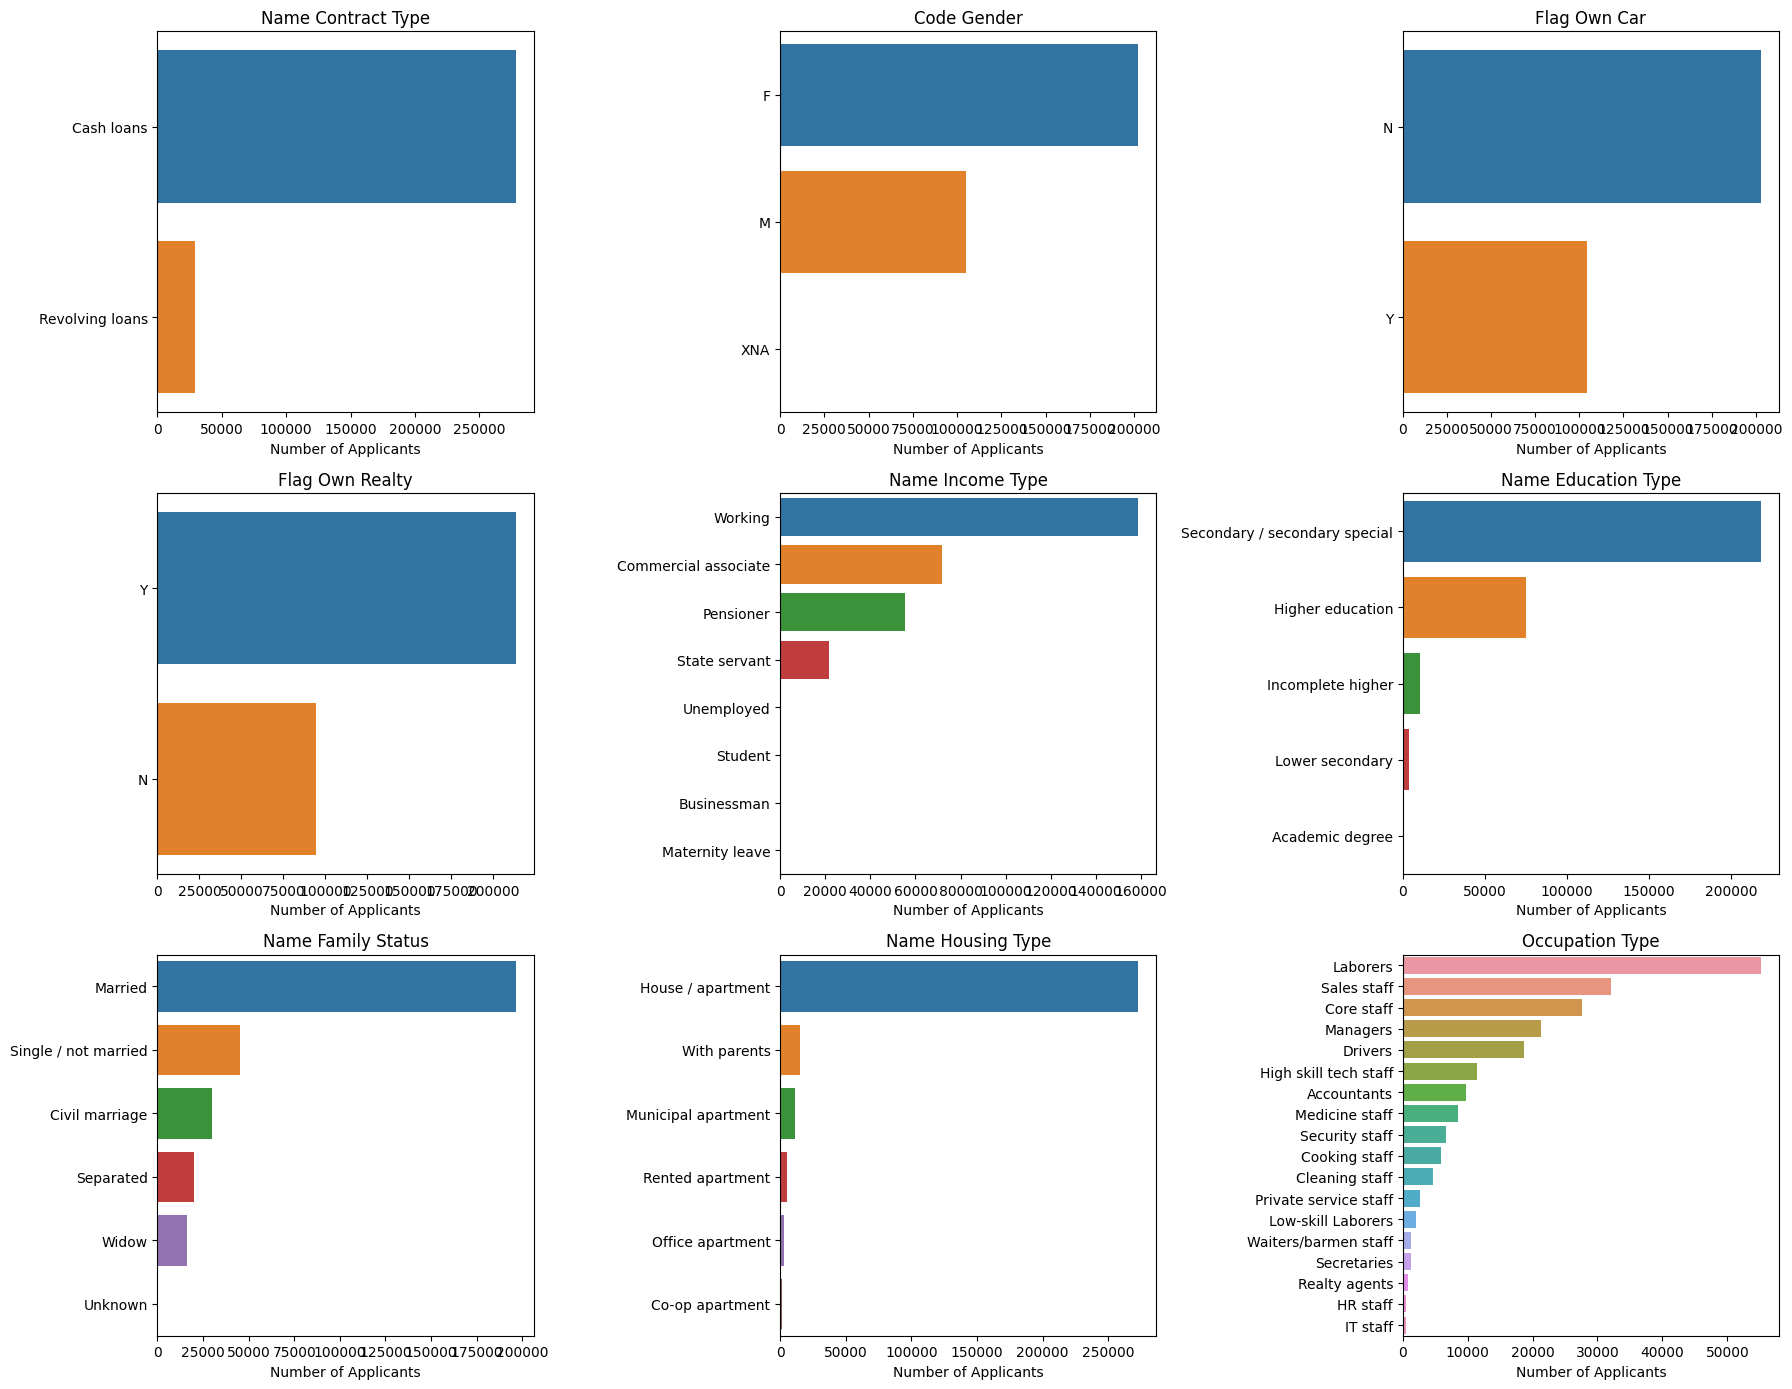

In [23]:
categorical_features = [
    "NAME_CONTRACT_TYPE",   # Loan type
    "CODE_GENDER",          # Gender
    "FLAG_OWN_CAR",         # Car ownership
    "FLAG_OWN_REALTY",      # Property ownership
    "NAME_INCOME_TYPE",     # Income source
    "NAME_EDUCATION_TYPE",  # Education level
    "NAME_FAMILY_STATUS",   # Family status
    "NAME_HOUSING_TYPE",    # Housing situation
    "OCCUPATION_TYPE"       # Occupation
]

# Create bar charts
fig, axes = plt.subplots(3, 3, figsize=(18, 14))

for ax, col in zip(axes.flatten(), categorical_features):
    order = application_train[col].value_counts().index

    sns.countplot(
        data=application_train,
        y=col,
        order=order,
        ax=ax
    )

    ax.set_title(col.replace("_", " ").title())
    ax.set_xlabel("Number of Applicants")
    ax.set_ylabel("")

plt.tight_layout()
plt.show()

## Target Correlation

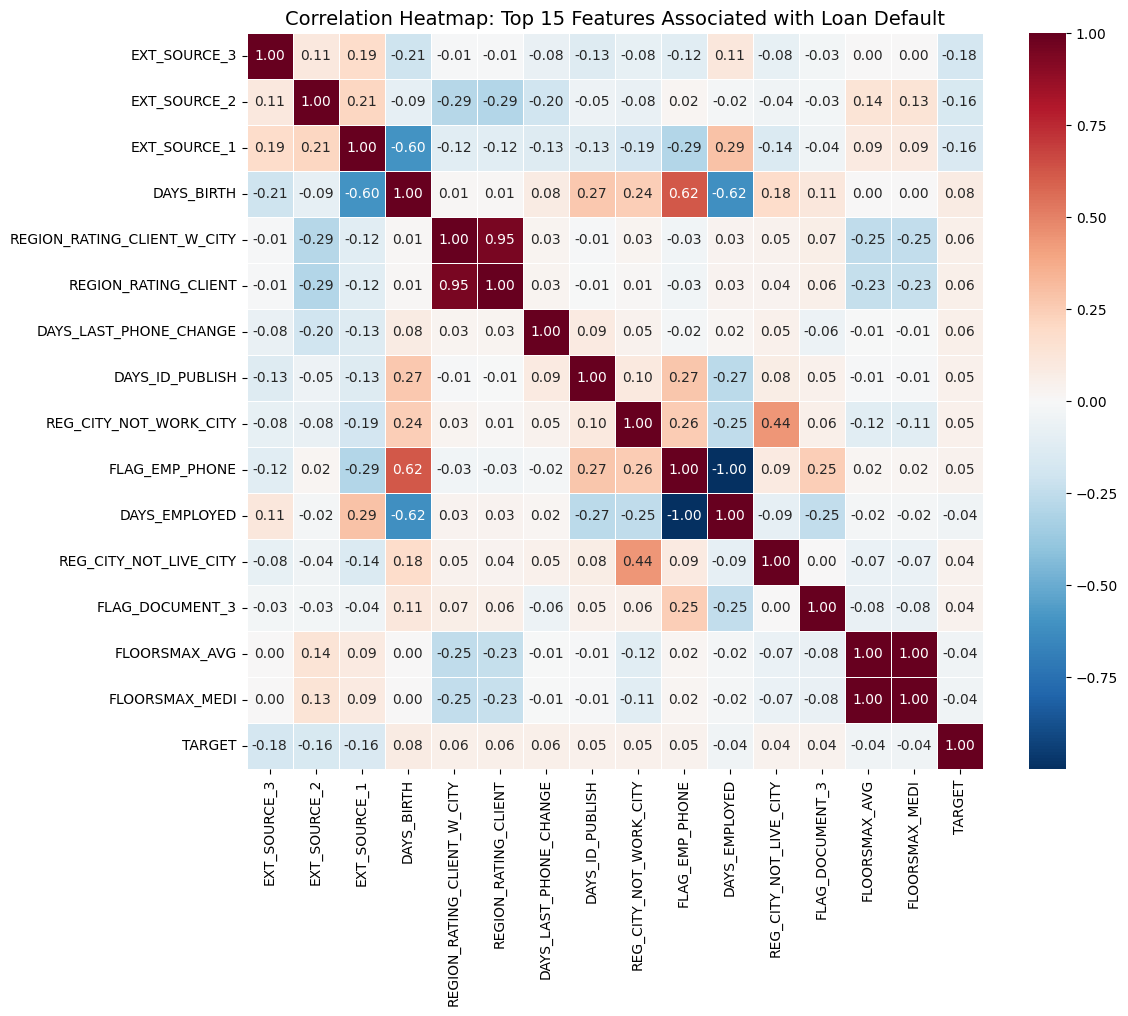

,Correlation with TARGET
DAYS_BIRTH,0.078239
REGION_RATING_CLIENT_W_CITY,0.060893
REGION_RATING_CLIENT,0.058899
DAYS_LAST_PHONE_CHANGE,0.055218
DAYS_ID_PUBLISH,0.051457
REG_CITY_NOT_WORK_CITY,0.050994
FLAG_EMP_PHONE,0.045982
REG_CITY_NOT_LIVE_CITY,0.044395
FLAG_DOCUMENT_3,0.044346
DAYS_REGISTRATION,0.041975


In [27]:
# Select numerical columns only
numeric_data = application_train.select_dtypes(include=["int64", "float64"])

# Calculate correlations with TARGET
correlations = numeric_data.corr()["TARGET"]

# Select 15 features with strongest absolute correlations
top_features = correlations.drop("TARGET").abs().nlargest(15).index

# Create correlation matrix
corr_matrix = numeric_data[list(top_features) + ["TARGET"]].corr()

# Plot heatmap
plt.figure(figsize=(12, 10))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="RdBu_r",
    center=0,
    fmt=".2f",
    linewidths=0.5,
    square=True
)

plt.title(
    "Correlation Heatmap: Top 15 Features Associated with Loan Default",
    fontsize=14
)

plt.tight_layout()
plt.show()


# Sort correlations from highest to lowest
correlation_ranking = correlations.drop("TARGET").sort_values(
    ascending=False
)

display(correlation_ranking.to_frame(name="Correlation with TARGET"))

## Target Comparison

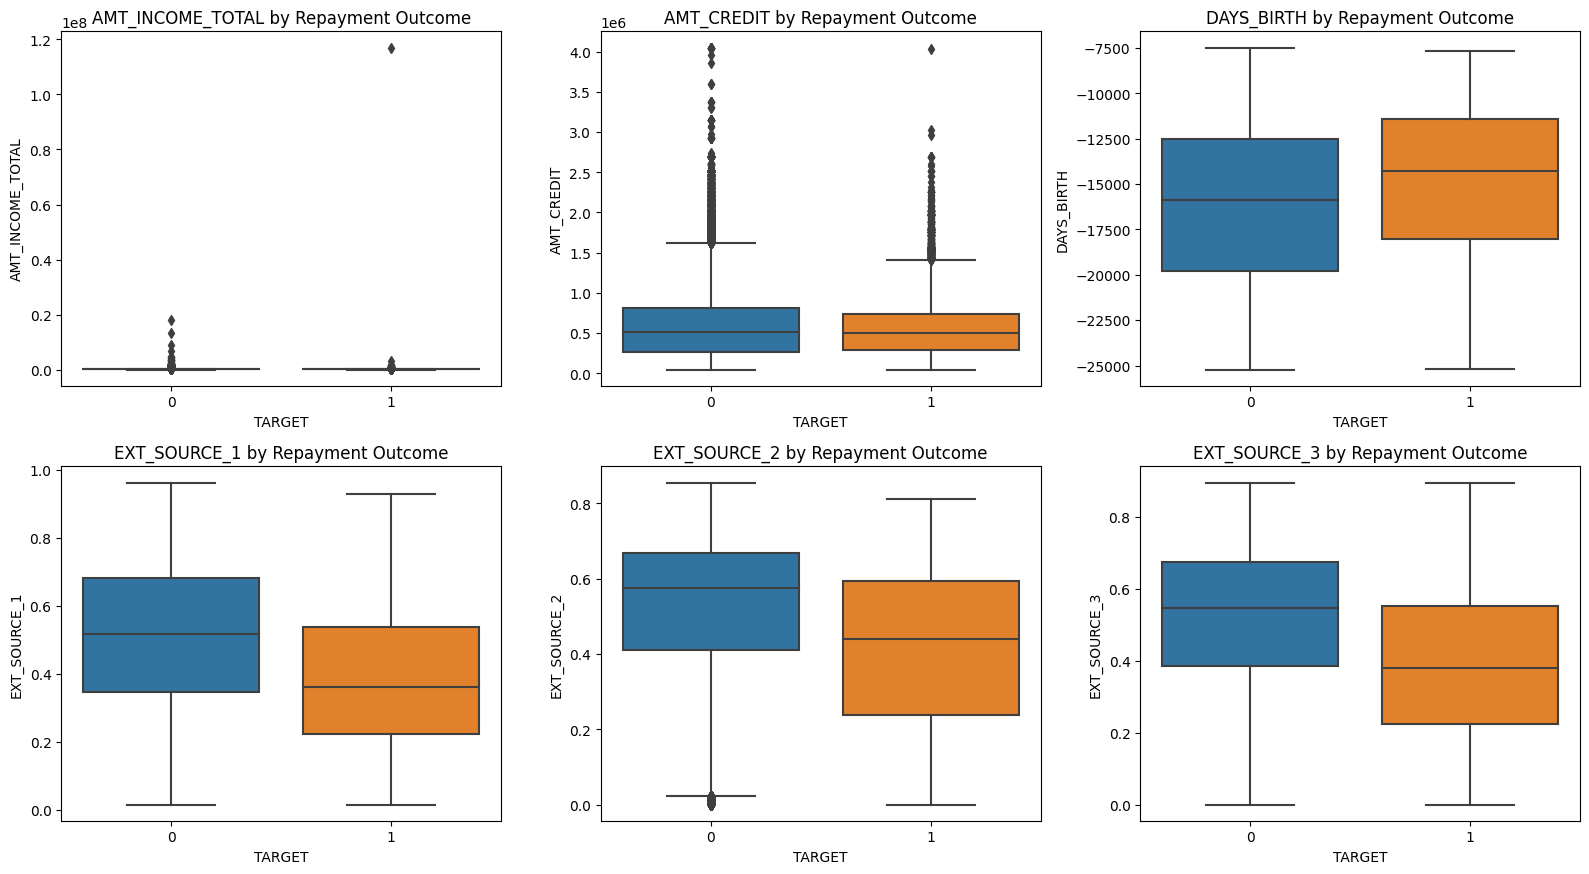

In [28]:
# Compare numerical features by TARGET
features_to_compare = [
    "AMT_INCOME_TOTAL",
    "AMT_CREDIT",
    "DAYS_BIRTH",
    "EXT_SOURCE_1",
    "EXT_SOURCE_2",
    "EXT_SOURCE_3"
]

fig, axes = plt.subplots(2, 3, figsize=(16, 9))

for ax, col in zip(axes.flatten(), features_to_compare):
    sns.boxplot(
        data=application_train,
        x="TARGET",
        y=col,
        ax=ax
    )
    ax.set_title(f"{col} by Repayment Outcome")

plt.tight_layout()
plt.show()

## Age

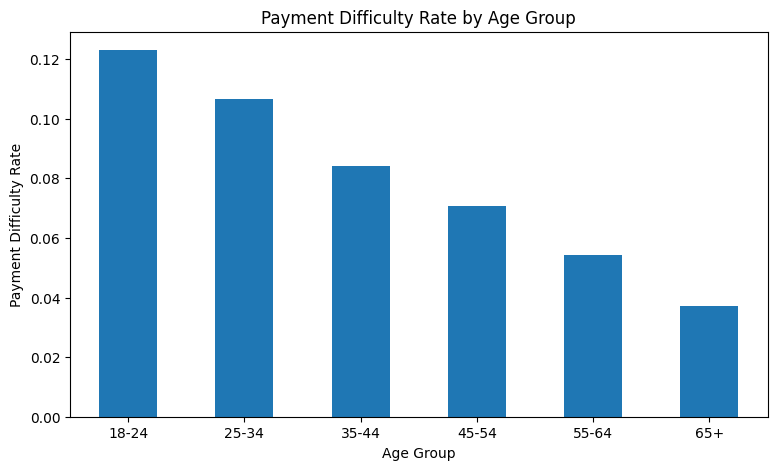

In [29]:
# Convert age from negative days to years
application_train["AGE_YEARS"] = (
    -application_train["DAYS_BIRTH"] / 365
)

# Create age groups
application_train["AGE_GROUP"] = pd.cut(
    application_train["AGE_YEARS"],
    bins=[18, 25, 35, 45, 55, 65, 100],
    labels=["18-24", "25-34", "35-44", "45-54", "55-64", "65+"]
)

# Calculate payment difficulty rate
age_default_rate = application_train.groupby(
    "AGE_GROUP", observed=False
)["TARGET"].mean()

# Visualize
age_default_rate.plot(kind="bar", figsize=(9, 5))

plt.title("Payment Difficulty Rate by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Payment Difficulty Rate")
plt.xticks(rotation=0)
plt.show()

## Affordability

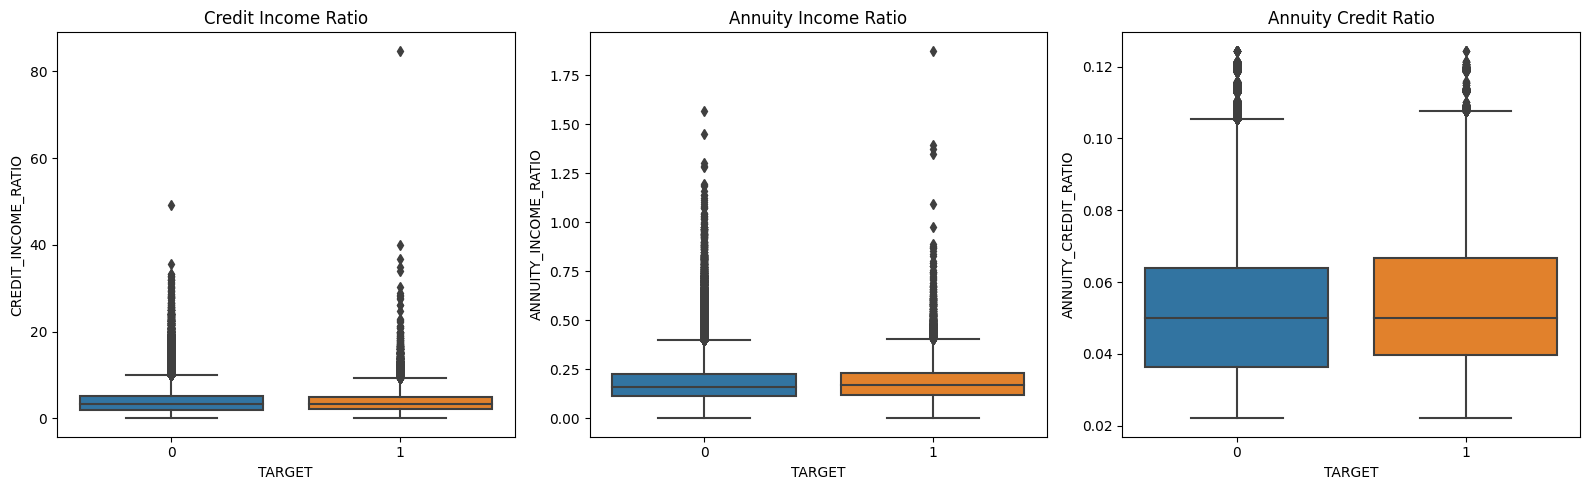

In [30]:
# Create financial ratios
application_train["CREDIT_INCOME_RATIO"] = (
    application_train["AMT_CREDIT"] /
    application_train["AMT_INCOME_TOTAL"].replace(0, np.nan)
)

application_train["ANNUITY_INCOME_RATIO"] = (
    application_train["AMT_ANNUITY"] /
    application_train["AMT_INCOME_TOTAL"].replace(0, np.nan)
)

application_train["ANNUITY_CREDIT_RATIO"] = (
    application_train["AMT_ANNUITY"] /
    application_train["AMT_CREDIT"].replace(0, np.nan)
)

# Compare ratios with TARGET
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, col in zip(
    axes,
    ["CREDIT_INCOME_RATIO", "ANNUITY_INCOME_RATIO",
     "ANNUITY_CREDIT_RATIO"]
):
    sns.boxplot(data=application_train, x="TARGET", y=col, ax=ax)
    ax.set_title(col.replace("_", " ").title())

plt.tight_layout()
plt.show()

## Default Rates by Categorical Variables

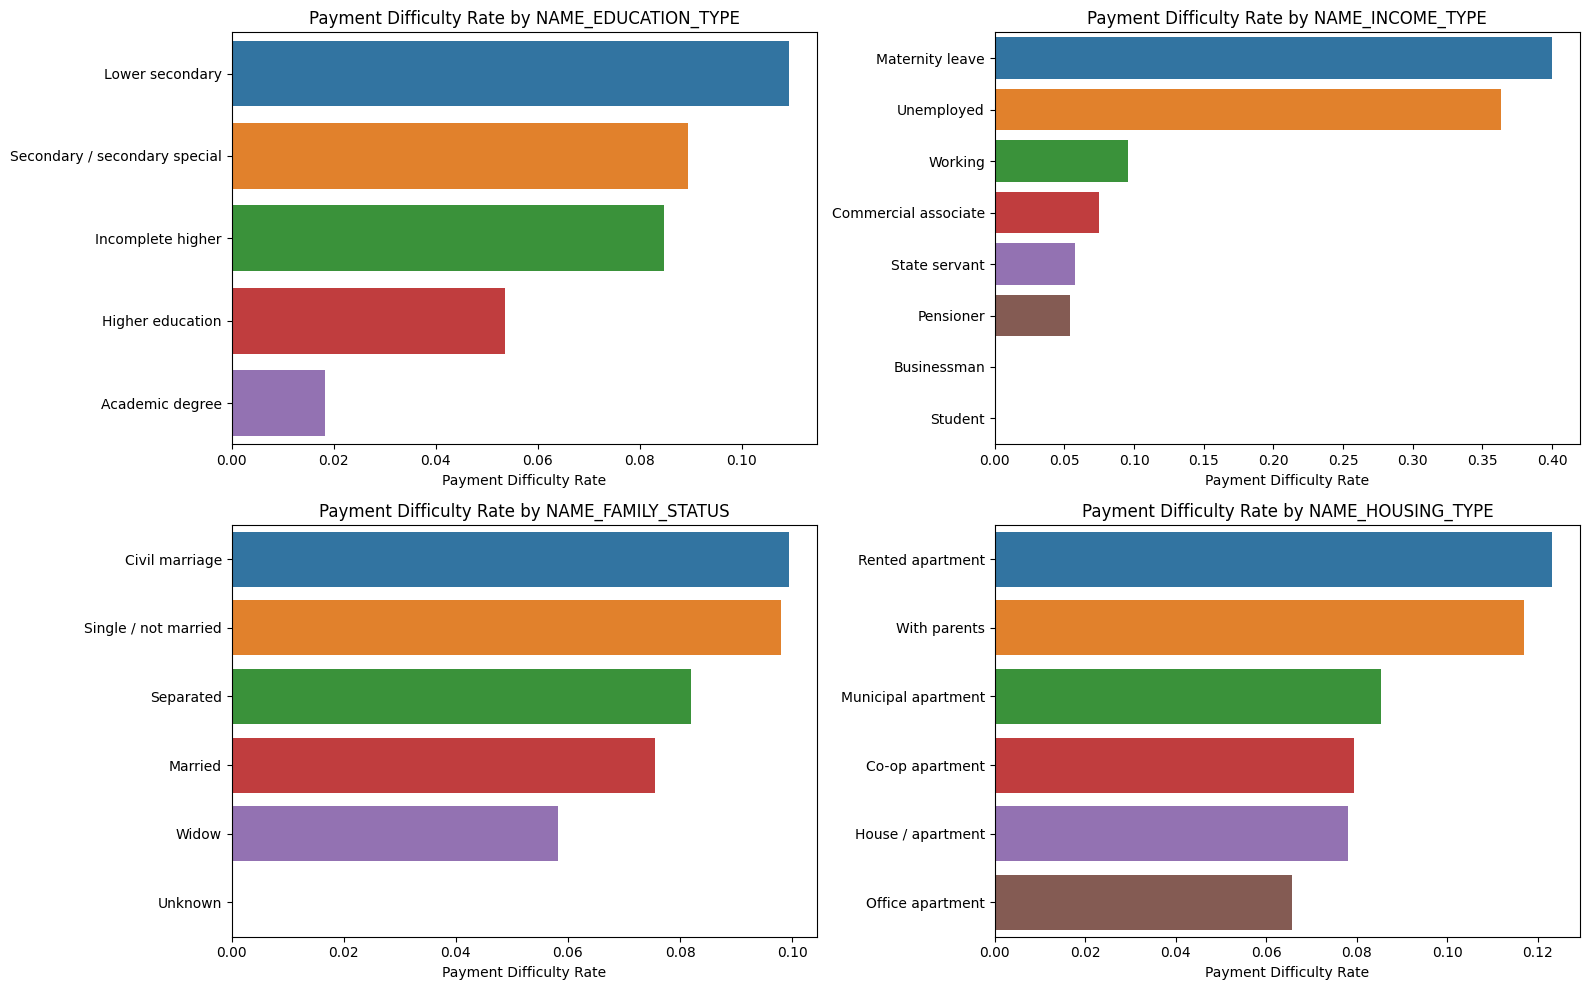

In [32]:
categorical_features = [
    "NAME_EDUCATION_TYPE",
    "NAME_INCOME_TYPE",
    "NAME_FAMILY_STATUS",
    "NAME_HOUSING_TYPE"
]

fig, axes = plt.subplots(2, 2, figsize=(16, 10))

for ax, col in zip(axes.flatten(), categorical_features):

    default_rate = application_train.groupby(col)["TARGET"].mean(
    ).sort_values(ascending=False)

    sns.barplot(
        x=default_rate.values,
        y=default_rate.index,
        ax=ax
    )

    ax.set_title(f"Payment Difficulty Rate by {col}")
    ax.set_xlabel("Payment Difficulty Rate")
    ax.set_ylabel("")

plt.tight_layout()
plt.show()

# Define Metrics

# Baseline Pipelines

# Report

![Team](team.png)